In [165]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy

today = date.today()

In [108]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data, keepdims=True))
    return fig

Load data

In [34]:
filename = '/home/ctrader/region_similarity/data/rank_based/hg38.25kb.maxMean.CT20230118.sorted.bed'
f = open(filename, 'r')
regions = []
for line in f.readlines():
    r = line.strip().split('\t')
    regions.append(r)
f.close()
regions = np.array(regions)

In [53]:
def print_coords(i):
    c = regions[i]
    return c[0] + ':' + c[1] + '-' + c[2]

In [11]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_mapped_path = datadir + 'regions_25kb_CT20230118.DHSsignalmapped.bed'
DHS_hdf5 = datadir + 'regions_25kb_CT20230119.DHSsignal.z.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
epi_hdf5 = datadir + 'regions_25kb_CT20230119.epilogos.maxstateperbin.officialstateorder.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'

f = open(DHS_mapped_path, 'r')
DHS_factor_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

epi_factor_order = np.array(['TssA', 'TssFlnk', 'TssFlnkU', 
                             'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 
                             'EnhG2', 'EnhA1', 'EnhA2', 'EnhWk', 
                             'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 
                             'ReprPC', 'ReprPCWk', 'Quies'])

In [273]:
#load the data

DHS_z_hdf5 = h5py.File(DHS_hdf5, 'r')
DHS_ranks = DHS_z_hdf5['ranked_data'][:]
DHS_max_ranks = DHS_z_hdf5['max_ranks'][:]
DHS_z_hdf5.close()


epi_z_hdf5 = h5py.File(epi_hdf5, 'r')
epi_ranks = epi_z_hdf5['ranked_data'][:]
epi_max_ranks = epi_z_hdf5['max_ranks'][:]
epi_z_hdf5.close()

In [13]:
print(DHS_ranks.shape, epi_ranks.shape)

(88036, 16) (88036, 18)


Bad regions

In [321]:
for i in np.argsort(np.mean(percents, axis=1))[:10]:
    print(i, print_coords(i), np.round(np.mean(percents, axis=1)[i], 4))

75473 chr8:6969078-6994078 0.0236
10635 chr10:120774688-120799688 0.0236
86496 chrX:105960608-105985809 0.0236
76524 chr8:40867281-40892281 0.0236
64066 chr5:144212237-144237237 0.0237
86539 chrX:107293770-107318770 0.0237
33697 chr18:50456830-50481830 0.0238
15526 chr12:13853666-13878666 0.0238
9570 chr10:87108243-87133243 0.0238
85429 chrX:71465950-71490950 0.0238


In [323]:
roi = 75473

Top region for cardiac DHSs and Active Enhancer 2

In [31]:
cardiac_ind = np.where(DHS_factor_order=='Cardiac')[0][0]
ae2_ind = np.where(epi_factor_order=='EnhA2')[0][0]
print(cardiac_ind, ae2_ind)

1 9


In [60]:
DHS_factor_order[9]

'Primitive_embryonic'

In [64]:
DHS_percent = DHS_ranks / DHS_max_ranks
epi_percent = epi_ranks / epi_max_ranks
ave_card_ae2_per = ((DHS_percent[:, cardiac_ind]) + 
                      (epi_percent[:, ae2_ind])) / 2
for ind in np.argsort(-ave_card_ae2_per)[:20]:
    print(ind,
          print_coords(ind), '\t', 
          np.round(DHS_percent[ind, cardiac_ind], 4), 
          np.round(epi_percent[ind, ae2_ind], 4), 
          np.round(ave_card_ae2_per[ind], 4))
    
# region #2 looks great

5503 chr1:202033872-202058872 	 0.9991 0.9996 0.9993
43637 chr2:237883758-237908758 	 0.9951 0.9962 0.9957
18417 chr12:109112195-109137195 	 0.9913 0.9992 0.9953
51533 chr3:123383153-123408153 	 0.9971 0.9928 0.995
27910 chr16:15805543-15830543 	 0.9897 0.9942 0.9919
60198 chr5:16520291-16545291 	 0.9911 0.992 0.9915
22030 chr13:110337253-110362253 	 0.9852 0.9948 0.99
81160 chr9:68738084-68763084 	 0.9906 0.9782 0.9844
32076 chr17:75632720-75657720 	 0.9696 0.9968 0.9832
7104 chr10:4656408-4681408 	 0.9686 0.9968 0.9827
45319 chr20:54113261-54138261 	 0.9637 0.9991 0.9814
9556 chr10:86664043-86689043 	 0.9669 0.992 0.9795
33138 chr18:32349237-32374237 	 0.9641 0.9909 0.9775
79725 chr9:567400-592400 	 0.9775 0.9759 0.9767
665 chr1:21890307-21915307 	 0.9947 0.956 0.9753
3625 chr1:116459978-116484978 	 0.9801 0.9705 0.9753
43444 chr2:231628089-231653089 	 0.9676 0.9806 0.9741
70226 chr6:163941368-163966368 	 0.9585 0.989 0.9737
7132 chr10:5597437-5622437 	 0.9778 0.9676 0.9727
66689 chr

In [350]:
roi = 43637
# roi = 9556

Join datasets

In [351]:
t = time.time()
joined_ranks = np.hstack((DHS_ranks, epi_ranks))
joined_max_ranks = np.append(DHS_max_ranks, epi_max_ranks)
joined_factor_order = np.append(DHS_factor_order, epi_factor_order)
print(time.time() - t)
print(joined_ranks.shape, joined_max_ranks.shape)

0.09662055969238281
(88036, 34) (34,)


Percent

In [352]:
t = time.time()
percents = joined_ranks / joined_max_ranks
print(time.time()-t)
print(percents.shape)

0.03883647918701172
(88036, 34)


Convolution

In [353]:
roi_percents = percents[roi]
print(roi_percents)

[0.         0.99514392 0.         0.66383725 0.         0.52395245
 0.99432125 0.59183781 0.20755554 0.         0.         0.
 0.53919694 0.11055091 0.         0.         0.         0.
 0.         0.         0.         0.50847276 0.         0.
 0.8488382  0.99617619 0.         0.54220703 0.23444614 0.
 0.         0.         0.         0.        ]


In [354]:
t = time.time()
roi_conv_all = percents * roi_percents
print(time.time()-t)

0.06301164627075195


Fusion

In [355]:
t = time.time()
roi_sim_all = 1 - np.prod(1 - roi_conv_all, axis=1)
print(time.time()-t)

0.07195091247558594


Score distribution

DescribeResult(nobs=88036, minmax=(0.0, 0.9999999795333187), mean=0.5388635027290006, variance=0.11748282751094795, skewness=-0.21293541559913948, kurtosis=-1.3374608826933578)
ModeResult(mode=array([0.]), count=array([9073]))


Text(0.5, 1.0, 'Score Distribution for ROI 43637')

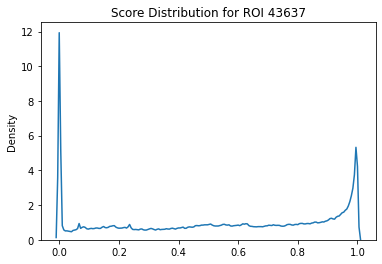

In [356]:
fig = kde_wrapper(roi_sim_all)
plt.title('Score Distribution for ROI ' + str(roi))

In [357]:
len(roi_sim_all)

88036

In [358]:
print(len(roi_sim_all[roi_sim_all>0]))
print(len(roi_sim_all[roi_sim_all>0.9]))
print(len(roi_sim_all[roi_sim_all>0.99]))

78963
18913
5689


In [359]:
for region in np.argsort(-roi_sim_all)[:11]:
    inds_over_thresh = np.where(roi_conv_all[region] > 0.9)[0]
    print(region,
          np.round(roi_sim_all[region], 9),
          len(inds_over_thresh),
          joined_factor_order[inds_over_thresh],
          percents[region][inds_over_thresh],
          np.round(np.max(roi_conv_all[region]), 4),
          print_coords(region)
         )

43637 0.99999998 3 ['Cardiac' 'Neural' 'EnhA2'] [0.99514392 0.99432125 0.99617619] 0.9924 chr2:237883758-237908758
6520 0.999999113 2 ['Cardiac' 'Neural'] [0.97037089 0.97577544] 0.9702 chr1:235038853-235086885
32129 0.99999875 2 ['Cardiac' 'Neural'] [0.99739602 0.95877511] 0.9926 chr17:77308518-77333518
5503 0.999998655 2 ['Cardiac' 'EnhA2'] [0.99908509 0.99960272] 0.9958 chr1:202033872-202058872
36854 0.999998417 2 ['Cardiac' 'Neural'] [0.99978887 0.99985623] 0.9949 chr2:16050478-16075478
64239 0.999998085 2 ['Neural' 'EnhA2'] [0.96747295 0.98544967] 0.9817 chr5:149781637-149806637
45110 0.999997797 2 ['Neural' 'EnhA2'] [0.99849046 0.97824899] 0.9928 chr20:47410456-47435456
49406 0.999997674 3 ['Cardiac' 'Neural' 'EnhA2'] [0.94454219 0.9556482  0.98679049] 0.983 chr3:52001384-52026384
31534 0.999997233 2 ['Cardiac' 'Neural'] [0.97853473 0.952701  ] 0.9738 chr17:57880639-57905639
36861 0.999996878 2 ['Cardiac' 'Neural'] [0.99957773 0.99960464] 0.9947 chr2:16295132-16320132
30999 0.999

0
7
258
5401
82370


Text(0.5, 1.0, 'Number of factors filtering')

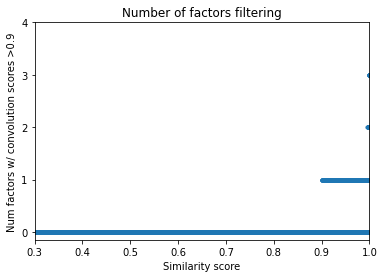

In [360]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.count_nonzero(roi_conv_all > 0.9, axis=1), s=10)

plt.xlim([0.3, 1])
plt.yticks([0, 1, 2, 3, 4])

plt.xlabel('Similarity score')
plt.ylabel('Num factors w/ convolution scores >0.9')
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==4))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==3))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==2))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==1))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==0))
plt.title('Number of factors filtering')

In [361]:
top_inds = np.argsort(-roi_sim_all)[:100]
top_inds = np.append(roi, top_inds[top_inds!=roi])

top_regions = regions[top_inds]
top_factors_per_region = []
for ind in top_inds:
    factors_over_thresh = np.where(roi_conv_all[ind] > 0.9)[0]
    top_factors_per_region.append('/'.join(joined_factor_order[factors_over_thresh]))
top_factors_per_region = np.array(top_factors_per_region)
top_regions = np.hstack((top_regions, top_factors_per_region.reshape(-1, 1)))

In [362]:
# top_regions

In [363]:
def roiurl_fusion(top_regions):
    today = date.today()
    query_region = '_'.join(top_regions[0, :3])
    roiurl_name = 'convolution_fusion_similarities_region_' + query_region + '_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path_epi = 'https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    link_path_index = 'https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    print(link_path_epi)
    print(link_path_index)
    return # link_path_epi, link_path_index

In [364]:
roiurl_fusion(top_regions)

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr2_237883758_237908758_25kb_CT20230126.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr2_237883758_237908758_25kb_CT20230126.bed


Text(0.5, 1.0, 'Max convolution score filtering')

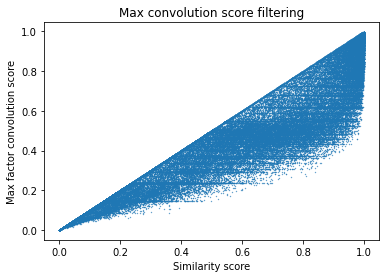

In [365]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.max(roi_conv_all, axis=1), s=0.1)

# plt.xlim([0.9, 1])
# plt.ylim([0.5, 1])
plt.xlabel('Similarity score')
plt.ylabel('Max factor convolution score')
plt.title('Max convolution score filtering')